In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from collections import Counter
import os
import time
import ast
from scipy.stats import randint

In [2]:
from tools import read_dag_file, add_risk_parameters, compute_topological_indicators, visualize_dag

In [3]:
sns.set_theme(palette='tab10',style='whitegrid',font='sans-serif')

## DT Dataset (Vanhoucke 2015)
The datasets **DC1** and **DC2** described in the paper by Vanhoucke et al. (2016) are artificial static datasets designed for research on the **Resource-Constrained Project Scheduling Problem with Discounted Cash flows (RCPSPDC)**. The dataset contains projects from 10 to 100 activities randomly generated.

References:
- Vanhoucke, M., Coelho, J., & Batselier, J. (2016). An overview of project data for integrated project management and control. The Journal of Modern Project Management, 3(3), 158-158.
- [Dataset source](https://www.projectmanagement.ugent.be/research/project_scheduling/rcpsp)


6 **Network Topology parameters** proposed by Vanhoucke (2008):
- I1	Number of activities	
- SP	Serial-Parallel Network Indicator	
- AD	Activity distribution Indicator	
- LA	Length arcs indicator	
- I5	I5 indicator	
- TF	Total float indicator	

In [4]:
# Metadata
df_metadata = pd.read_csv('data/dc_dataset_metadata.txt', sep='\t')

In [8]:
topological_index=['#Act','SP','AD','LA','I5','TF']

Project file: mv1008.rcp

Topological metrics by Vanhoucke
      #Act    SP    AD    LA    I5    TF
1007    30  0.45  0.36  0.14  0.67  0.24

Topological metrics by own calculation
I1: 30, SP: 0.4483, AD: 0.3558, LA: 0.1429, I5: 0.6724, TF: 0.2404

AON of the project


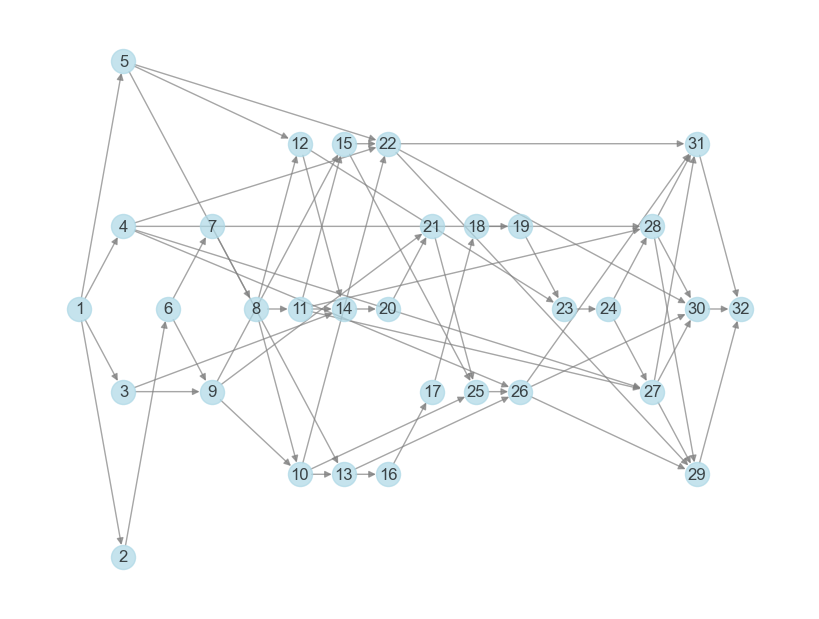

In [11]:
# Check own calculation of topological indices
id=df_metadata.sample(1).index
file=df_metadata.loc[id,'FileName'].values[0]
if '\\' in file:
    file = file.split('\\')[1]
print(f"Project file: {file}")
print("\nTopological metrics by Vanhoucke")
print(df_metadata.loc[id,topological_index])
G = read_dag_file(f"data\DC_all\{file}")
print("\nTopological metrics by own calculation")
I1, SP, AD, LA, I5, TF= compute_topological_indicators(G)
print(f"I1: {I1}, SP: {SP:0.4f}, AD: {AD:0.4f}, LA: {LA:0.4f}, I5: {I5:0.4f}, TF: {TF:0.4f}")
print(f"\nAON of the project")
visualize_dag(G)


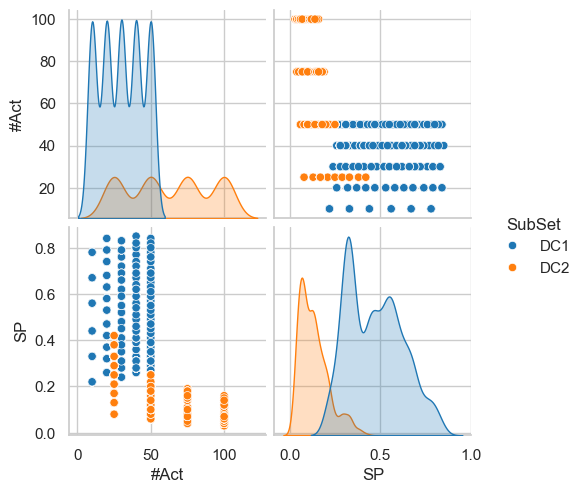

In [12]:
sns.pairplot(df_metadata[['#Act','SP','SubSet']],hue='SubSet')

## RanGen2 dataset

In [15]:
data=[]
for i,file in enumerate([f for f in os.listdir('data\\rangen') if f.endswith('.rcp')]):
    dt={}
    dt['FileName']=file
    G = read_dag_file(f"data\\rangen\{file}")
    I1, SP, AD, LA, I5, TF= compute_topological_indicators(G)
    dt['I1']=I1
    dt['SP']=SP
    dt['AD']=AD
    dt['LA']=LA
    dt['I5']=I5 
    dt['TF']=TF
    data.append(dt)
df_rangen=pd.DataFrame(data)


In [16]:
df_rangen.head(2)

,FileName,I1,SP,AD,LA,I5,TF
0,Pat1.rcp,20,0.052632,0.444444,0.038462,1.0,0.611111
1,Pat10.rcp,20,0.052632,0.222222,0.034091,1.0,0.444444


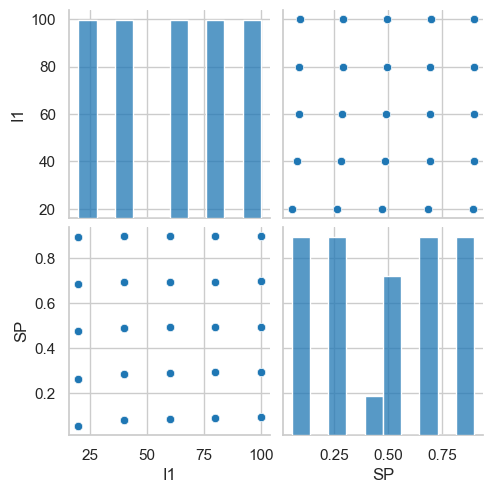

In [17]:
sns.pairplot(df_rangen[['I1','SP']])

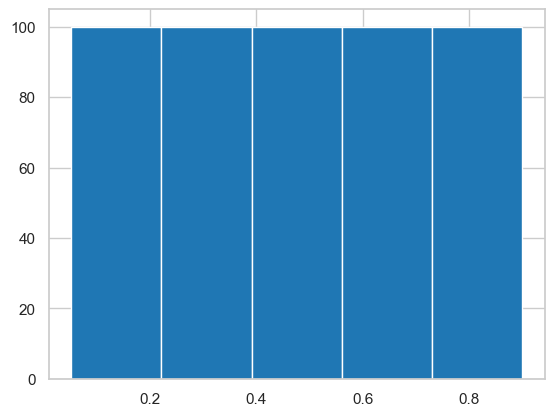

In [21]:
plt.hist(df_rangen['SP'],bins=5);

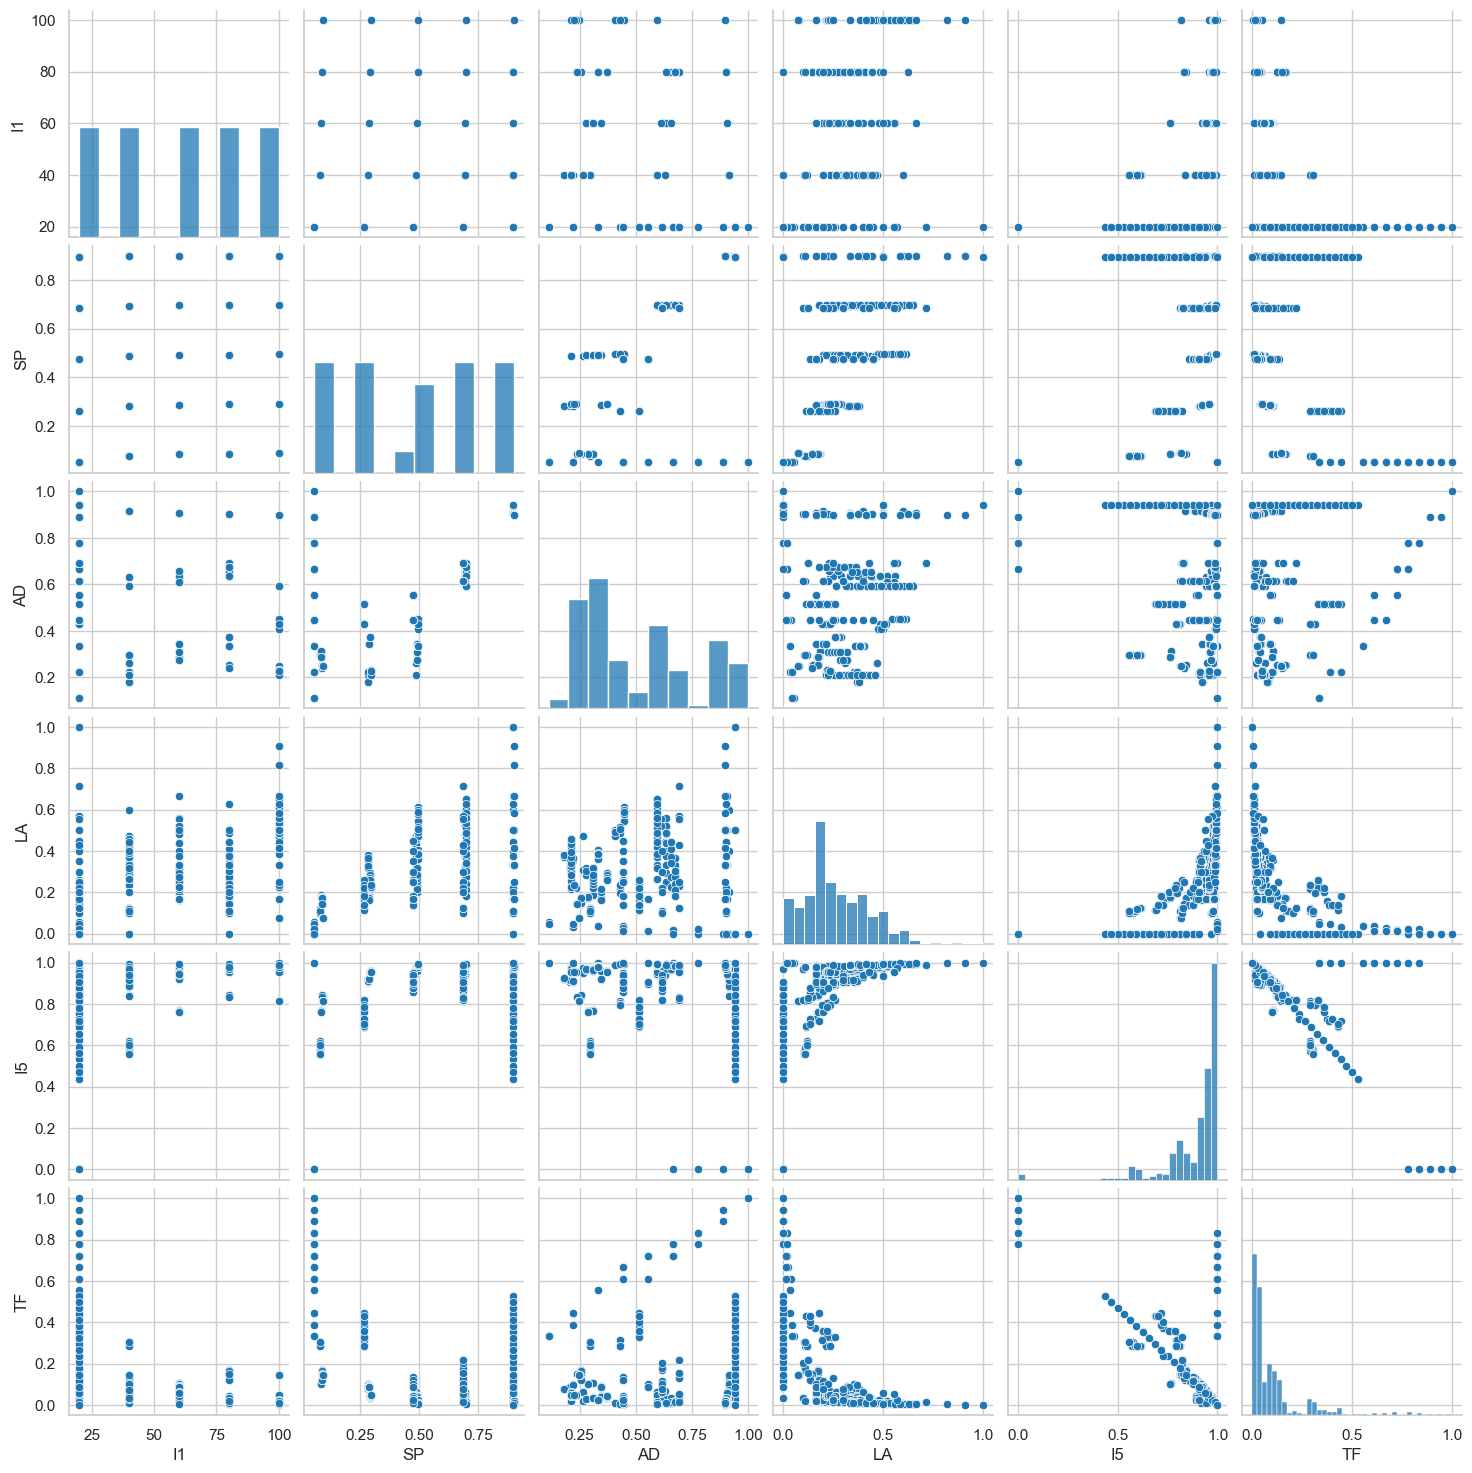

In [22]:
sns.pairplot(df_rangen[['I1','SP','AD','LA','I5','TF']])